In [ ]:
import os
import re
import time
import json
import pickle
import getpass
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

In [ ]:
from collections import Counter
from nltk.corpus import stopwords
from nltk.sentiment.vader import SentimentIntensityAnalyzer

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")
nltk.download("stopwords", quiet=True)
nltk.download("vader_lexicon", quiet=True)

print("Setup complete.")

Setup complete.


In [ ]:
API_KEY = getpass("Enter SerpApi API key: ").strip()
PLACE_ID = "ChIJLU7jZClu5kcR4PcOOO6p3I0"
MAX_REVIEWS = 2000
BASE_URL = "https://serpapi.com/search.json"

if not API_KEY:
    raise ValueError("SerpApi API key is required.")

def fetch_reviews_page(token=None, retries=3):
    params = {
        "engine": "google_maps_reviews",
        "place_id": PLACE_ID,
        "hl": "en",
        "api_key": API_KEY,
    }
    if token:
        params["next_page_token"] = token

    for attempt in range(retries):
        try:
            response = requests.get(BASE_URL, params=params, timeout=30)
            response.raise_for_status()
            data = response.json()
            if data.get("error"):
                raise RuntimeError(data["error"])
            return data
        except (requests.exceptions.RequestException, ValueError, RuntimeError) as exc:
            print(f"Attempt {attempt + 1}/{retries} failed: {exc}")
            if attempt < retries - 1:
                time.sleep(2 * (attempt + 1))
    return {}

reviews = []
next_token = None
seen_tokens = set()

while len(reviews) < MAX_REVIEWS:
    page = fetch_reviews_page(next_token)
    batch = page.get("reviews", [])

    if not batch:
        print("No further reviews returned; stopping.")
        break

    reviews.extend(batch[:MAX_REVIEWS - len(reviews)])
    print(f"Collected {len(reviews)} reviews so far.")

    next_token = page.get("serpapi_pagination", {}).get("next_page_token")
    if not next_token or next_token in seen_tokens:
        print("No new pagination token; stopping.")
        break

    seen_tokens.add(next_token)
    time.sleep(2)

df_raw = pd.DataFrame(reviews)
print("Raw dataset shape:", df_raw.shape)
display(df_raw.head())

Collected 10 reviews so far.
Collected 20 reviews so far.
Collected 30 reviews so far.
Collected 40 reviews so far.
Collected 50 reviews so far.
Collected 60 reviews so far.
Collected 70 reviews so far.
Collected 80 reviews so far.
Collected 90 reviews so far.
Collected 100 reviews so far.
Collected 110 reviews so far.
Collected 120 reviews so far.
Collected 130 reviews so far.
Collected 140 reviews so far.
Collected 150 reviews so far.
Collected 160 reviews so far.
Collected 170 reviews so far.
Collected 180 reviews so far.
Collected 190 reviews so far.
Collected 200 reviews so far.
Collected 210 reviews so far.
Collected 220 reviews so far.
Collected 230 reviews so far.
Collected 240 reviews so far.
Collected 250 reviews so far.
Collected 260 reviews so far.
Collected 270 reviews so far.
Collected 280 reviews so far.
Collected 290 reviews so far.
Collected 300 reviews so far.
Collected 310 reviews so far.
Collected 320 reviews so far.
Collected 330 reviews so far.
Collected 340 revie

,position,link,rating,date,iso_date,iso_date_of_last_edit,images,source,review_id,user,snippet,extracted_snippet,details,likes,videos
0,1,https://www.google.com/maps/reviews/data=!4m8!...,5.0,a month ago,2026-09-26T16:10:50Z,2026-09-26T16:10:50Z,[https://lh3.googleusercontent.com/grass-cs/AA...,Google,Ci9DQUlRQUNvZENodHljRjlvT21GTk9VaGlaVVJyZFhsel...,"{'name': 'Reshma Rachu', 'link': 'https://www....",Visiting the Eiffel Tower was truly the highli...,{'original': 'Visiting the Eiffel Tower was tr...,"{'visited_on': 'Weekend', 'wait_time': 'No wai...",0,NaN
1,2,https://www.google.com/maps/reviews/data=!4m8!...,5.0,a month ago,2026-10-05T13:30:41Z,2026-10-05T13:30:41Z,[https://lh3.googleusercontent.com/grass-cs/AA...,Google,Ci9DQUlRQUNvZENodHljRjlvT25wQlFXNXpRM2haVlRoeV...,"{'name': 'Reza Md Al Amin Sarker', 'link': 'ht...",Visiting the Eiffel Tower was a truly unforget...,{'original': 'Visiting the Eiffel Tower was a ...,"{'visited_on': 'Weekend', 'wait_time': '1 hr+'...",0,NaN
2,3,https://www.google.com/maps/reviews/data=!4m8!...,5.0,2 months ago,2026-08-28T13:10:31Z,2026-08-28T13:10:31Z,[https://lh3.googleusercontent.com/grass-cs/AA...,Google,Ci9DQUlRQUNvZENodHljRjlvT2tOME1sVnhhWEZpZEVaSV...,"{'name': 'Kamal Shah', 'link': 'https://www.go...",We visited the Eiffel Tower with our three kid...,{'original': 'We visited the Eiffel Tower with...,"{'visited_on': 'Weekday', 'wait_time': 'No wait'}",0,NaN
3,4,https://www.google.com/maps/reviews/data=!4m8!...,5.0,Edited 2 months ago,2026-09-25T01:12:22Z,2026-09-25T01:12:22Z,[https://lh3.googleusercontent.com/grass-cs/AA...,Google,Ci9DQUlRQUNvZENodHljRjlvT2xOR1kzRkhXWEpxT1Y5d2...,"{'name': 'Eslam Nassar', 'link': 'https://www....",Visiting the Eiffel Tower in winter was an unf...,{'original': 'Visiting the Eiffel Tower in win...,"{'visited_on': 'Public holiday', 'reservation_...",0,NaN
4,5,https://www.google.com/maps/reviews/data=!4m8!...,4.0,a week ago,2026-11-14T19:10:54Z,2026-11-14T19:10:54Z,[https://lh3.googleusercontent.com/grass-cs/AA...,Google,Ci9DQUlRQUNvZENodHljRjlvT2pGbUxUUTFhVzh4TkRseF...,"{'name': 'Shaan Ehtesham', 'link': 'https://ww...",Visiting the Eiffel Tower in Paris is genuinel...,{'original': 'Visiting the Eiffel Tower in Par...,NaN,0,NaN


In [ ]:
import pandas as pd
from google.colab import files

# Convert collected reviews into DataFrame
df = pd.DataFrame(reviews)

# Export CSV
df.to_csv(
    "google_maps_reviews.csv",
    index=False,
    encoding="utf-8-sig"
)

# Export Excel
df.to_excel(
    "google_maps_reviews.xlsx",
    index=False,
    engine="openpyxl"
)

print("✅ Dataset exported successfully!")
print("Total Reviews:", len(df))
print("Dataset Shape:", df.shape)

# Download CSV
files.download("google_maps_reviews.csv")

# Download Excel
files.download("google_maps_reviews.xlsx")

✅ Dataset exported successfully!
Total Reviews: 2000
Dataset Shape: (2000, 15)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Save raw extraction outputs
df_raw.to_excel("reviews.xlsx", index=False)
with open("reviews.pkl", "wb") as file:
    pickle.dump(df_raw, file)

print("Saved reviews.xlsx and reviews.pkl")
print("Columns:", df_raw.columns.tolist())
display(df_raw.sample(min(2, len(df_raw)), random_state=42) if len(df_raw) else df_raw)

Saved reviews.xlsx and reviews.pkl
Columns: ['position', 'link', 'rating', 'date', 'iso_date', 'iso_date_of_last_edit', 'images', 'source', 'review_id', 'user', 'snippet', 'extracted_snippet', 'details', 'likes', 'videos']


,position,link,rating,date,iso_date,iso_date_of_last_edit,images,source,review_id,user,snippet,extracted_snippet,details,likes,videos
1860,1,https://www.google.com/maps/reviews/data=!4m8!...,5.0,Edited 2 years ago,2024-07-23T22:46:36Z,2024-07-23T22:46:36Z,[https://lh3.googleusercontent.com/grass-cs/AA...,Google,ChZDSUhNMG9nS0VJQ0FnSUR6dC1EU0pREAE,"{'name': 'Lloyd Dias', 'link': 'https://www.go...",The most iconic landmark in Paris. It's a must...,{'original': 'The most iconic landmark in Pari...,"{'visited_on': 'Weekday', 'wait_time': 'No wai...",0,[{'thumbnail': 'https://lh3.googleusercontent....
353,4,https://www.google.com/maps/reviews/data=!4m8!...,5.0,4 months ago,2026-07-12T18:18:16Z,2026-07-12T18:18:16Z,[https://lh3.googleusercontent.com/grass-cs/AA...,Google,Ci9DQUlRQUNvZENodHljRjlvT2xsQ05ISnhNWEJ1ZWpONl...,"{'name': 'Mark Zanchi', 'link': 'https://www.g...",We had an awesome time. They closed the Eiffel...,{'original': 'We had an awesome time. They clo...,"{'visited_on': 'Weekend', 'wait_time': '10–30 ...",0,NaN


In [ ]:
print("Raw shape:", df_raw.shape)
display(df_raw.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

# SerpApi Google Maps reviews commonly use `snippet` for review text.
# Change COL_TEXT below if your actual dataset uses another field.
COL_TEXT = "snippet"
COL_RATING = "rating"
COL_DATE = "iso_date_of_last_edit"
COL_AUTHOR = "user"

if COL_TEXT not in df_raw.columns:
    raise KeyError(f"Review text column {COL_TEXT!r} not found. Available columns: {df_raw.columns.tolist()}")
if COL_RATING not in df_raw.columns:
    raise KeyError(f"Rating column {COL_RATING!r} not found. Available columns: {df_raw.columns.tolist()}")

working = {
    "Text": df_raw[COL_TEXT].copy(),
    "Rating": df_raw[COL_RATING].copy(),
}
if COL_DATE in df_raw.columns:
    working["Date"] = df_raw[COL_DATE].copy()
if COL_AUTHOR in df_raw.columns:
    working["Author"] = df_raw[COL_AUTHOR].copy()

df = pd.DataFrame(working)
df["Text"] = df["Text"].astype("string").str.strip()
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")

if "Date" in df.columns:
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce", utc=True)



Raw shape: (2000, 15)


,missing_count
videos,1218
details,424
images,81
rating,0
date,0
link,0
position,0
iso_date_of_last_edit,0
iso_date,0
source,0


In [ ]:
# --- Data Cleaning ---

# Create a working copy and map columns to 'Text' and 'Rating'
df = pd.DataFrame({
    "Text": df_raw["snippet"].copy() if "snippet" in df_raw.columns else df_raw.get("extracted_snippet", ""),
    "Rating": df_raw["rating"].copy()
})

if "iso_date_of_last_edit" in df_raw.columns:
    df["Date"] = df_raw["iso_date_of_last_edit"].copy()
if "user" in df_raw.columns:
    df["Author"] = df_raw["user"].copy()

# Convert Text to string
df["Text"] = df["Text"].astype("string").str.strip()

# Convert Rating to numeric
df["Rating"] = pd.to_numeric(
    df["Rating"],
    errors="coerce"
)

# Before cleaning
before_count = len(df)

print("Before Cleaning:", before_count)


# 1. Remove missing Text and Rating
df = df.dropna(
    subset=["Text", "Rating"]
).copy()


# 2. Remove empty reviews
df = df[df["Text"].str.strip().ne("")].copy()


# 3. Keep valid ratings (1 to 5)
df = df[df["Rating"].between(1, 5)].copy()


# 4. Remove exact duplicate reviews
df = df.drop_duplicates(
    subset=["Text", "Rating"],
    keep="first"
).reset_index(drop=True)


# --- Cleaning Summary ---

after_count = len(df)
removed_count = before_count - after_count

print("\n========== CLEANING SUMMARY ==========")
print("Before Cleaning :", before_count)
print("After Cleaning  :", after_count)
print("Removed Rows    :", removed_count)
print("Final Shape     :", df.shape)

print("\nMissing Values:")
display(df.isnull().sum())

print("\nCleaned Dataset:")
display(df.head(5))

Before Cleaning: 2000

========== CLEANING SUMMARY ==========
Before Cleaning : 2000
After Cleaning  : 1997
Removed Rows    : 3
Final Shape     : (1997, 4)

Missing Values:


,0
Text,0
Rating,0
Date,0
Author,0



Cleaned Dataset:


,Text,Rating,Date,Author
0,Visiting the Eiffel Tower was truly the highli...,5.0,2026-09-26T16:10:50Z,"{'name': 'Reshma Rachu', 'link': 'https://www...."
1,Visiting the Eiffel Tower was a truly unforget...,5.0,2026-10-05T13:30:41Z,"{'name': 'Reza Md Al Amin Sarker', 'link': 'ht..."
2,We visited the Eiffel Tower with our three kid...,5.0,2026-08-28T13:10:31Z,"{'name': 'Kamal Shah', 'link': 'https://www.go..."
3,Visiting the Eiffel Tower in winter was an unf...,5.0,2026-09-25T01:12:22Z,"{'name': 'Eslam Nassar', 'link': 'https://www...."
4,Visiting the Eiffel Tower in Paris is genuinel...,4.0,2026-11-14T19:10:54Z,"{'name': 'Shaan Ehtesham', 'link': 'https://ww..."


In [ ]:
df

,Text,Rating,Date,Author
0,Visiting the Eiffel Tower was truly the highli...,5.0,2026-09-26T16:10:50Z,"{'name': 'Reshma Rachu', 'link': 'https://www...."
1,Visiting the Eiffel Tower was a truly unforget...,5.0,2026-10-05T13:30:41Z,"{'name': 'Reza Md Al Amin Sarker', 'link': 'ht..."
2,We visited the Eiffel Tower with our three kid...,5.0,2026-08-28T13:10:31Z,"{'name': 'Kamal Shah', 'link': 'https://www.go..."
3,Visiting the Eiffel Tower in winter was an unf...,5.0,2026-09-25T01:12:22Z,"{'name': 'Eslam Nassar', 'link': 'https://www...."
4,Visiting the Eiffel Tower in Paris is genuinel...,4.0,2026-11-14T19:10:54Z,"{'name': 'Shaan Ehtesham', 'link': 'https://ww..."
...,...,...,...,...
1992,A visit to the Eiffel Tower is an unforgettabl...,5.0,2026-04-26T11:33:53Z,"{'name': 'Nina Elbaz', 'link': 'https://www.go..."
1993,Unique experience to visit the iconic Eiffel t...,5.0,2025-06-24T13:24:49Z,"{'name': 'Francina', 'link': 'https://www.goog..."
1994,"The staff was rude, but at least the line is s...",4.0,2025-07-17T20:14:45Z,"{'name': 'Kris Skov Olsson', 'link': 'https://..."
1995,Glad to finally be adding my pictures of the E...,5.0,2023-01-03T18:23:12Z,"{'name': 'Vinny F', 'link': 'https://www.googl..."


Rating Distribution:


,Review Count
Rating,
1.0,3
2.0,11
3.0,49
4.0,231
5.0,1703


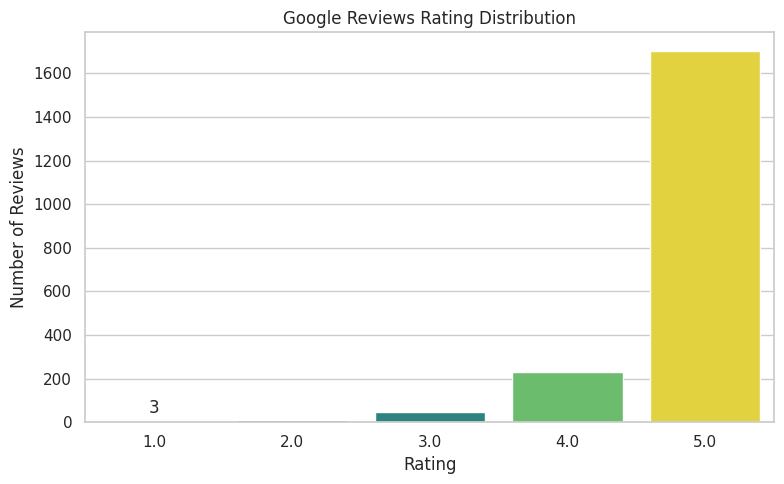

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

rating_counts = df["Rating"].value_counts().sort_index()

print("Rating Distribution:")
display(rating_counts.to_frame("Review Count"))

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    hue=rating_counts.index,
    palette="viridis",
    legend=False
)

plt.title("Google Reviews Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")

ax.bar_label(ax.containers[0], padding=3)

plt.tight_layout()
plt.show()

In [ ]:
# Missing Values Analysis

missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_df = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

print("Missing Values Analysis:")
display(missing_df)

Missing Values Analysis:


,Missing Values,Missing Percentage
Text,0,0.0
Rating,0,0.0
Date,0,0.0
Author,0,0.0


In [ ]:
# Duplicate Reviews Analysis

duplicate_count = df.duplicated(
    subset=["Text", "Rating"]
).sum()

print("Total Reviews:", len(df))
print("Duplicate Reviews:", duplicate_count)
print("Unique Reviews:", len(df) - duplicate_count)

Total Reviews: 1997
Duplicate Reviews: 0
Unique Reviews: 1997


In [ ]:
# Review Text Length Analysis

df["Review_Length"] = df["Text"].astype(str).apply(len)

print("Review Length Statistics:")
display(df["Review_Length"].describe())

Review Length Statistics:


,Review_Length
count,1997.000000
mean,426.318978
std,394.155497
min,34.000000
25%,202.000000
50%,313.000000
75%,506.000000
max,3992.000000


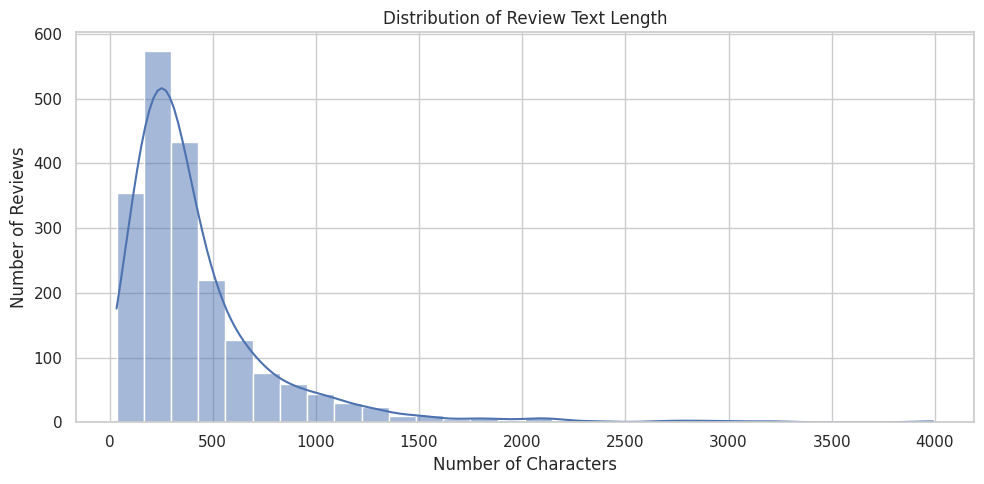

In [ ]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Review_Length",
    bins=30,
    kde=True
)

plt.title("Distribution of Review Text Length")
plt.xlabel("Number of Characters")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

Monthly Review Counts:


/tmp/ipykernel_5187/971003686.py:11: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["Month"] = df["Date"].dt.to_period("M").astype(str)


,Review Count
Month,
2018-07,1
2019-09,1
2022-10,5
2023-01,5
2023-02,1
2023-03,1
2023-04,1
2023-05,5
2023-06,3


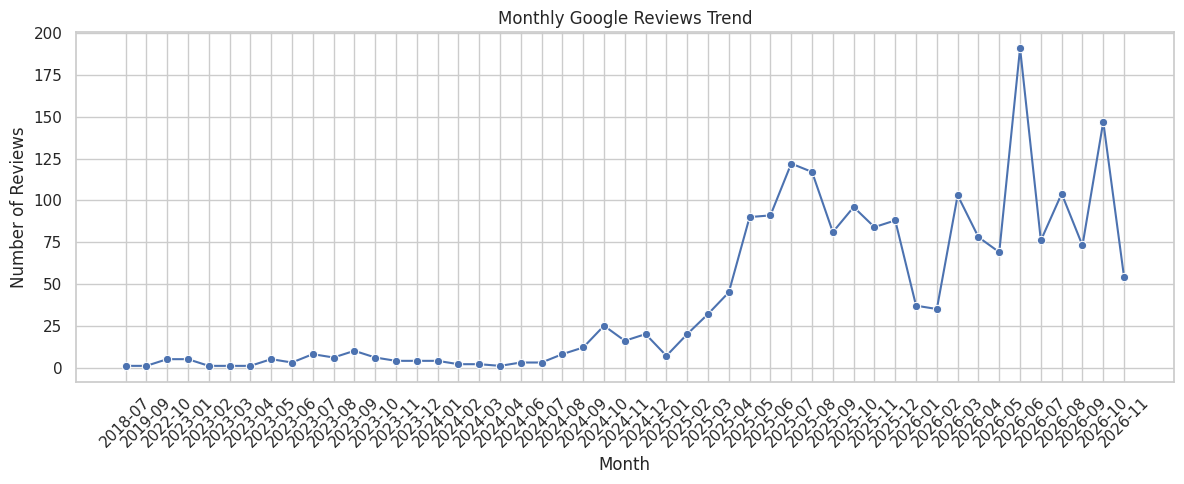

In [ ]:
# Convert Date column to datetime

df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce",
    utc=True
)

# Extract Year and Month

df["Month"] = df["Date"].dt.to_period("M").astype(str)

# Monthly Review Count

monthly_reviews = df.groupby("Month").size()

print("Monthly Review Counts:")
display(monthly_reviews.to_frame("Review Count"))

# Visualization

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_reviews.index,
    y=monthly_reviews.values,
    marker="o"
)

plt.title("Monthly Google Reviews Trend")
plt.xlabel("Month")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [ ]:
print("Total Reviews:", len(df))

print("Invalid Dates:", df["Date"].isna().sum())

print("Date Range:")
print("Minimum:", df["Date"].min())
print("Maximum:", df["Date"].max())

print("Monthly Total:", monthly_reviews.sum())

Total Reviews: 1997
Invalid Dates: 0
Date Range:
Minimum: 2018-07-03 19:21:58+00:00
Maximum: 2026-11-22 18:57:14+00:00
Monthly Total: 1997


In [ ]:
import re
import nltk
import pandas as pd

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Download required NLTK resources
nltk.download("punkt")
nltk.download("punkt_tab")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("omw-1.4")

# Initialize tools
stop_words = set(stopwords.words("english"))

# Preserve negative words
stop_words = stop_words - {"not", "no", "nor", "never"}

lemmatizer = WordNetLemmatizer()

# Text preprocessing function
def preprocess_text(text):

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove special characters and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    # Tokenization
    tokens = word_tokenize(text)

    # Stopword removal
    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Lemmatization
    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return " ".join(tokens)


# Apply preprocessing
df["Cleaned_Text"] = df["Text"].apply(preprocess_text)

display(df[["Text", "Cleaned_Text"]].head())

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


,Text,Cleaned_Text
0,Visiting the Eiffel Tower was truly the highli...,visiting eiffel tower truly highlight trip par...
1,Visiting the Eiffel Tower was a truly unforget...,visiting eiffel tower truly unforgettable expe...
2,We visited the Eiffel Tower with our three kid...,visited eiffel tower three kid definitely one ...
3,Visiting the Eiffel Tower in winter was an unf...,visiting eiffel tower winter unforgettable exp...
4,Visiting the Eiffel Tower in Paris is genuinel...,visiting eiffel tower paris genuinely one icon...


In [ ]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk

nltk.download("vader_lexicon")

# Initialize VADER
sid = SentimentIntensityAnalyzer()

# Calculate Sentiment Score
df["Sentiment_score"] = df["Text"].apply(
    lambda x: sid.polarity_scores(str(x))["compound"]
)

# Generate Sentiment Labels
df["Sentiment_label"] = df["Sentiment_score"].apply(
    lambda s: "Positive" if s > 0.05
    else ("Negative" if s < -0.05 else "Neutral")
)

# Generate Sentiment Emoji
def sentiment_emoji(score):

    if score > 0.5:
        return "😊"

    if score > 0.05:
        return "🙂"

    if score < -0.5:
        return "😡"

    if score < -0.05:
        return "😕"

    return "😐"


df["Sentiment_emoji"] = df["Sentiment_score"].apply(
    sentiment_emoji
)

# Display Results
display(
    df[[
        "Text",
        "Sentiment_score",
        "Sentiment_label",
        "Sentiment_emoji"
    ]].head(10)
)

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


,Text,Sentiment_score,Sentiment_label,Sentiment_emoji
0,Visiting the Eiffel Tower was truly the highli...,0.9931,Positive,😊
1,Visiting the Eiffel Tower was a truly unforget...,0.9859,Positive,😊
2,We visited the Eiffel Tower with our three kid...,0.9972,Positive,😊
3,Visiting the Eiffel Tower in winter was an unf...,0.9022,Positive,😊
4,Visiting the Eiffel Tower in Paris is genuinel...,0.9957,Positive,😊
5,Visiting the Eiffel Tower in the morning was s...,0.9815,Positive,😊
6,The Eiffel Tower is truly one of the most icon...,0.9796,Positive,😊
7,Great day to visit - no queues - just turned u...,0.9272,Positive,😊
8,The Eiffel Tower was one of the highlights of ...,0.7527,Positive,😊
9,I'd recommend everyone to book tickets in adva...,0.9374,Positive,😊


In [ ]:
# Sentiment Distribution

sentiment_counts = df["Sentiment_label"].value_counts()

print("Sentiment Distribution:")
display(sentiment_counts.to_frame("Review Count"))

# Sentiment Percentage

sentiment_percentage = (
    df["Sentiment_label"].value_counts(normalize=True) * 100
)

display(sentiment_percentage.to_frame("Percentage"))

Sentiment Distribution:


,Review Count
Sentiment_label,
Positive,1905
Negative,58
Neutral,34


,Percentage
Sentiment_label,
Positive,95.393090
Negative,2.904357
Neutral,1.702554


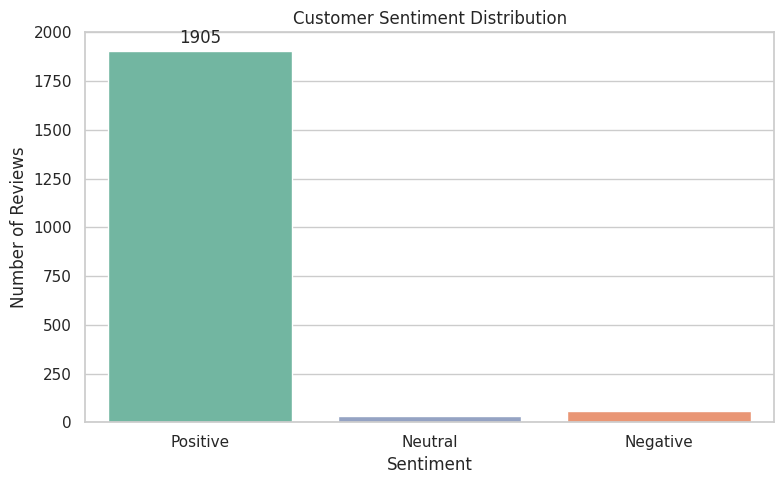

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x="Sentiment_label",
    hue="Sentiment_label",
    palette="Set2",
    order=["Positive", "Neutral", "Negative"],
    legend=False
)

plt.title("Customer Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

ax.bar_label(ax.containers[0], padding=3)

plt.tight_layout()
plt.show()

In [ ]:
!pip install -q transformers torch

In [ ]:
import torch
from transformers import pipeline

model_name = "cardiffnlp/twitter-roberta-base-sentiment-latest"

device = 0 if torch.cuda.is_available() else -1

sentiment_model = pipeline(
    "sentiment-analysis",
    model=model_name,
    tokenizer=model_name,
    device=device
)

print("Model Loaded Successfully!")
print("Device:", "GPU" if device == 0 else "CPU")

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  501MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Model Loaded Successfully!
Device: GPU


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'sample_data']


In [ ]:
import pandas as pd

df = pd.read_csv("/content/google_maps_reviews (1).csv")

print("Dataset Loaded Successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset Loaded Successfully!
Shape: (2000, 15)


,position,link,rating,date,iso_date,iso_date_of_last_edit,images,source,review_id,user,snippet,extracted_snippet,details,likes,videos
0,1,https://www.google.com/maps/reviews/data=!4m8!...,5.0,a month ago,2026-09-26T16:10:50Z,2026-09-26T16:10:50Z,['https://lh3.googleusercontent.com/grass-cs/A...,Google,Ci9DQUlRQUNvZENodHljRjlvT21GTk9VaGlaVVJyZFhsel...,"{'name': 'Reshma Rachu', 'link': 'https://www....",Visiting the Eiffel Tower was truly the highli...,{'original': 'Visiting the Eiffel Tower was tr...,"{'visited_on': 'Weekend', 'wait_time': 'No wai...",0,NaN
1,2,https://www.google.com/maps/reviews/data=!4m8!...,5.0,a month ago,2026-10-05T13:30:41Z,2026-10-05T13:30:41Z,['https://lh3.googleusercontent.com/grass-cs/A...,Google,Ci9DQUlRQUNvZENodHljRjlvT25wQlFXNXpRM2haVlRoeV...,"{'name': 'Reza Md Al Amin Sarker', 'link': 'ht...",Visiting the Eiffel Tower was a truly unforget...,{'original': 'Visiting the Eiffel Tower was a ...,"{'visited_on': 'Weekend', 'wait_time': '1 hr+'...",0,NaN
2,3,https://www.google.com/maps/reviews/data=!4m8!...,5.0,2 months ago,2026-08-28T13:10:31Z,2026-08-28T13:10:31Z,['https://lh3.googleusercontent.com/grass-cs/A...,Google,Ci9DQUlRQUNvZENodHljRjlvT2tOME1sVnhhWEZpZEVaSV...,"{'name': 'Kamal Shah', 'link': 'https://www.go...",We visited the Eiffel Tower with our three kid...,"{'original': ""We visited the Eiffel Tower with...","{'visited_on': 'Weekday', 'wait_time': 'No wait'}",0,NaN
3,4,https://www.google.com/maps/reviews/data=!4m8!...,5.0,Edited 2 months ago,2026-09-25T01:12:22Z,2026-09-25T01:12:22Z,['https://lh3.googleusercontent.com/grass-cs/A...,Google,Ci9DQUlRQUNvZENodHljRjlvT2xOR1kzRkhXWEpxT1Y5d2...,"{'name': 'Eslam Nassar', 'link': 'https://www....",Visiting the Eiffel Tower in winter was an unf...,{'original': 'Visiting the Eiffel Tower in win...,"{'visited_on': 'Public holiday', 'reservation_...",0,NaN
4,5,https://www.google.com/maps/reviews/data=!4m8!...,4.0,a week ago,2026-11-14T19:10:54Z,2026-11-14T19:10:54Z,['https://lh3.googleusercontent.com/grass-cs/A...,Google,Ci9DQUlRQUNvZENodHljRjlvT2pGbUxUUTFhVzh4TkRseF...,"{'name': 'Shaan Ehtesham', 'link': 'https://ww...",Visiting the Eiffel Tower in Paris is genuinel...,"{'original': ""Visiting the Eiffel Tower in Par...",NaN,0,NaN


In [ ]:
import pandas as pd
from nltk.sentiment.vader import SentimentIntensityAnalyzer
import nltk

# 1. Map columns from raw dataset if they haven't been mapped yet
if "Text" not in df.columns:
    df = pd.DataFrame({
        "Text": df["snippet"].copy() if "snippet" in df.columns else df.get("extracted_snippet", ""),
        "Rating": df["rating"].copy()
    })
    if "iso_date_of_last_edit" in df.columns:
        df["Date"] = df["iso_date_of_last_edit"].copy()
    if "user" in df.columns:
        df["Author"] = df["user"].copy()

# 2. Re-apply cleaning steps
df["Text"] = df["Text"].astype("string").str.strip()
df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
df = df.dropna(subset=["Text", "Rating"]).copy()
df = df[df["Text"].str.strip().ne("")].copy()
df = df[df["Rating"].between(1, 5)].copy()
df = df.drop_duplicates(subset=["Text", "Rating"], keep="first").reset_index(drop=True)

# 3. Calculate VADER Sentiment
nltk.download("vader_lexicon", quiet=True)
sid = SentimentIntensityAnalyzer()
df["Sentiment_score"] = df["Text"].apply(lambda x: sid.polarity_scores(str(x))["compound"])
df["Sentiment_label"] = df["Sentiment_score"].apply(lambda s: "Positive" if s > 0.05 else ("Negative" if s < -0.05 else "Neutral"))

# 4. Run sentiment model prediction
texts = df["Text"].fillna("").astype(str).tolist()

results = sentiment_model(
    texts,
    batch_size=16,
    truncation=True,
    max_length=512
)

df["Transformer_Sentiment"] = [
    result["label"].capitalize()
    for result in results
]

df["Transformer_Score"] = [
    result["score"]
    for result in results
]

display(
    df[[
        "Text",
        "Sentiment_label",
        "Transformer_Sentiment",
        "Transformer_Score"
    ]].head(10)
)

,Text,Sentiment_label,Transformer_Sentiment,Transformer_Score
0,Visiting the Eiffel Tower was truly the highli...,Positive,Positive,0.983876
1,Visiting the Eiffel Tower was a truly unforget...,Positive,Positive,0.981857
2,We visited the Eiffel Tower with our three kid...,Positive,Positive,0.984431
3,Visiting the Eiffel Tower in winter was an unf...,Positive,Positive,0.985347
4,Visiting the Eiffel Tower in Paris is genuinel...,Positive,Positive,0.915147
5,Visiting the Eiffel Tower in the morning was s...,Positive,Positive,0.986922
6,The Eiffel Tower is truly one of the most icon...,Positive,Positive,0.981092
7,Great day to visit - no queues - just turned u...,Positive,Positive,0.979389
8,The Eiffel Tower was one of the highlights of ...,Positive,Positive,0.961558
9,I'd recommend everyone to book tickets in adva...,Positive,Positive,0.875650


In [ ]:
# VADER vs Transformer Comparison

print("VADER Distribution:")
print(df["Sentiment_label"].value_counts())

print("\nTransformer Distribution:")
print(df["Transformer_Sentiment"].value_counts())

# Model Agreement
df["Model_Agreement"] = (
    df["Sentiment_label"] == df["Transformer_Sentiment"]
)

agreement = df["Model_Agreement"].sum()
disagreement = len(df) - agreement

print("\nModel Comparison Results")
print("Total Reviews:", len(df))
print("Agreement:", agreement)
print("Disagreement:", disagreement)

print(
    "Agreement Percentage:",
    round((agreement / len(df)) * 100, 2), "%"
)

VADER Distribution:
Sentiment_label
Positive    1905
Negative      58
Neutral       34
Name: count, dtype: int64

Transformer Distribution:
Transformer_Sentiment
Positive    1824
Neutral       97
Negative      76
Name: count, dtype: int64

Model Comparison Results
Total Reviews: 1997
Agreement: 1799
Disagreement: 198
Agreement Percentage: 90.09 %


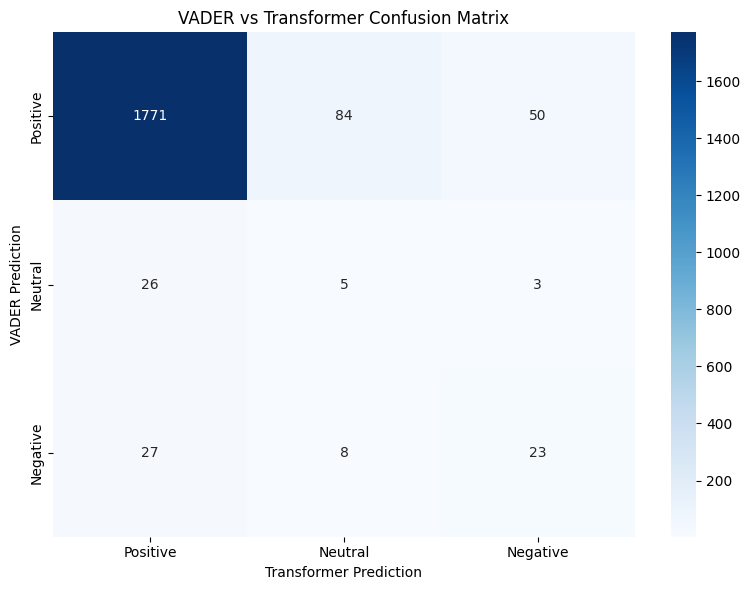

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

labels = ["Positive", "Neutral", "Negative"]

cm = confusion_matrix(
    df["Sentiment_label"],
    df["Transformer_Sentiment"],
    labels=labels
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)

plt.title("VADER vs Transformer Confusion Matrix")
plt.xlabel("Transformer Prediction")
plt.ylabel("VADER Prediction")

plt.tight_layout()
plt.show()

In [ ]:
# Identify Disagreement Reviews

disagreement_df = df[
    df["Sentiment_label"] != df["Transformer_Sentiment"]
].copy()

print("Total Disagreement Reviews:", len(disagreement_df))

display(
    disagreement_df[
        [
            "Text",
            "Sentiment_label",
            "Transformer_Sentiment",
            "Transformer_Score"
        ]
    ].head(10)
)

Total Disagreement Reviews: 198


,Text,Sentiment_label,Transformer_Sentiment,Transformer_Score
44,Not an inexpensive outing and I sure would not...,Positive,Neutral,0.437298
57,Plan to do lots of walking and lots of waiting...,Positive,Negative,0.768472
74,Been a while since I came here. It’s easy enou...,Positive,Neutral,0.551501
75,visited both in the day & night. note that ev...,Positive,Neutral,0.900630
83,"The Eiffel Tower is iconic, but the overall ex...",Positive,Negative,0.685168
99,The world famous Eiffel Tower is a sight to be...,Neutral,Positive,0.816842
101,It's a tower made of steel. Arrived here in su...,Negative,Positive,0.596181
116,"Nothing much to say is there, it's the tower! ...",Positive,Neutral,0.472274
146,We booked a walking tour. Not worth it. Just q...,Positive,Negative,0.643203
157,Must visit in afternoon & in night to see ligh...,Positive,Neutral,0.813625


In [ ]:
import re

# Define Theme Keywords

theme_keywords = {

    "Ticket & Pricing": [
        "ticket", "price", "expensive", "cheap",
        "cost", "booking", "book", "payment",
        "inexpensive", "fee"
    ],

    "Crowd & Waiting Time": [
        "crowd", "queue", "queues", "waiting",
        "wait", "busy", "line", "long wait"
    ],

    "Views & Experience": [
        "view", "beautiful", "amazing", "iconic",
        "experience", "panorama", "spectacular",
        "scenery", "highlight"
    ],

    "Visit Timing": [
        "morning", "evening", "afternoon",
        "night", "sunset", "winter", "summer",
        "day", "lights"
    ],

    "Accessibility & Facilities": [
        "stairs", "elevator", "lift", "wheelchair",
        "accessible", "toilet", "restroom",
        "facility", "access"
    ],

    "Staff & Service": [
        "staff", "employee", "guide",
        "service", "security", "helpful",
        "friendly", "rude"
    ]
}


# Theme Detection Function

def detect_themes(text):

    text = str(text).lower()

    matched_themes = []

    for theme, keywords in theme_keywords.items():

        for keyword in keywords:

            pattern = r"\b" + re.escape(keyword) + r"\b"

            if re.search(pattern, text):
                matched_themes.append(theme)
                break

    if not matched_themes:
        matched_themes.append("General Experience")

    return matched_themes


# Apply Theme Categorization

df["Themes"] = df["Text"].apply(detect_themes)

# Display Results

display(
    df[["Text", "Sentiment_label", "Themes"]].head(15)
)

print("Theme Categorization Completed!")

,Text,Sentiment_label,Themes
0,Visiting the Eiffel Tower was truly the highli...,Positive,"[Ticket & Pricing, Crowd & Waiting Time, Views..."
1,Visiting the Eiffel Tower was a truly unforget...,Positive,"[Views & Experience, Visit Timing]"
2,We visited the Eiffel Tower with our three kid...,Positive,"[Ticket & Pricing, Crowd & Waiting Time, Views..."
3,Visiting the Eiffel Tower in winter was an unf...,Positive,"[Views & Experience, Visit Timing]"
4,Visiting the Eiffel Tower in Paris is genuinel...,Positive,"[Ticket & Pricing, Crowd & Waiting Time, Views..."
5,Visiting the Eiffel Tower in the morning was s...,Positive,"[Views & Experience, Visit Timing]"
6,The Eiffel Tower is truly one of the most icon...,Positive,"[Views & Experience, Visit Timing]"
7,Great day to visit - no queues - just turned u...,Positive,"[Crowd & Waiting Time, Visit Timing]"
8,The Eiffel Tower was one of the highlights of ...,Positive,"[Ticket & Pricing, Views & Experience, Visit T..."
9,I'd recommend everyone to book tickets in adva...,Positive,"[Ticket & Pricing, Crowd & Waiting Time, Acces..."


Theme Categorization Completed!


In [ ]:
from collections import Counter

theme_counts = Counter(
    theme
    for themes in df["Themes"]
    for theme in themes
)

theme_df = pd.DataFrame(
    theme_counts.items(),
    columns=["Theme", "Review Count"]
).sort_values(
    by="Review Count",
    ascending=False
)

display(theme_df)

,Theme,Review Count
2,Views & Experience,1430
3,Visit Timing,995
1,Crowd & Waiting Time,552
4,Accessibility & Facilities,500
0,Ticket & Pricing,440
5,Staff & Service,244
6,General Experience,182


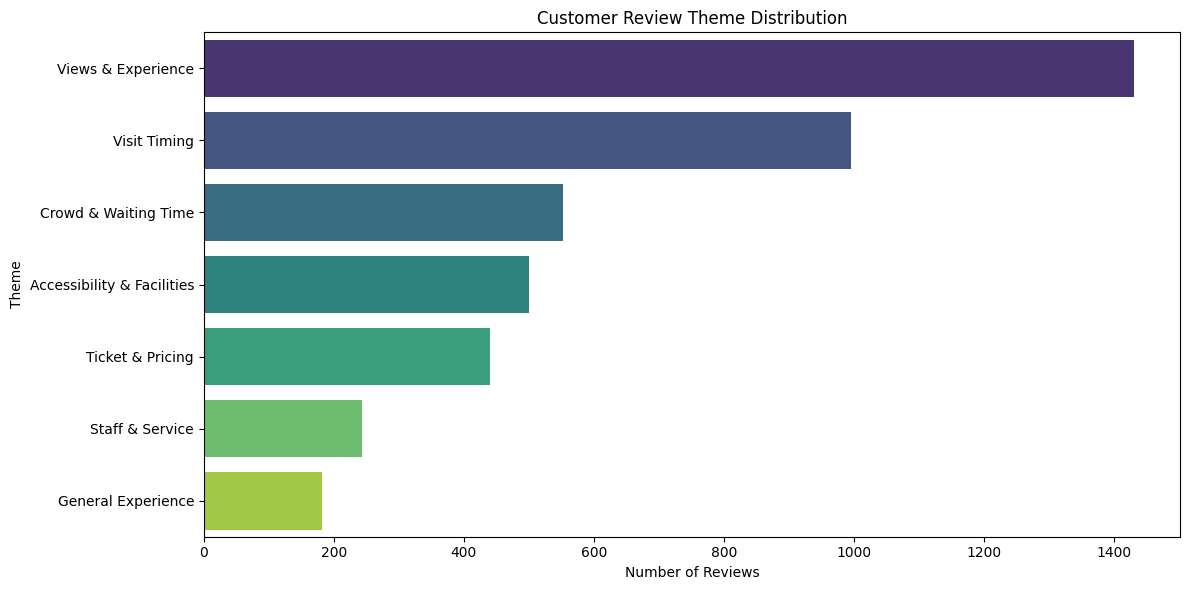

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=theme_df,
    x="Review Count",
    y="Theme",
    hue="Theme",
    palette="viridis",
    legend=False
)

plt.title("Customer Review Theme Distribution")
plt.xlabel("Number of Reviews")
plt.ylabel("Theme")

plt.tight_layout()
plt.show()

In [ ]:
# Expand themes into separate rows

theme_sentiment_df = df.explode("Themes")

# Group by Theme and Sentiment

theme_sentiment = pd.crosstab(
    theme_sentiment_df["Themes"],
    theme_sentiment_df["Sentiment_label"]
)

print("Sentiment by Theme:")
display(theme_sentiment)

Sentiment by Theme:


Sentiment_label,Negative,Neutral,Positive
Themes,,,
Accessibility & Facilities,18,3,479
Crowd & Waiting Time,15,2,535
General Experience,7,9,166
Staff & Service,9,2,233
Ticket & Pricing,15,6,419
Views & Experience,27,15,1388
Visit Timing,30,10,955


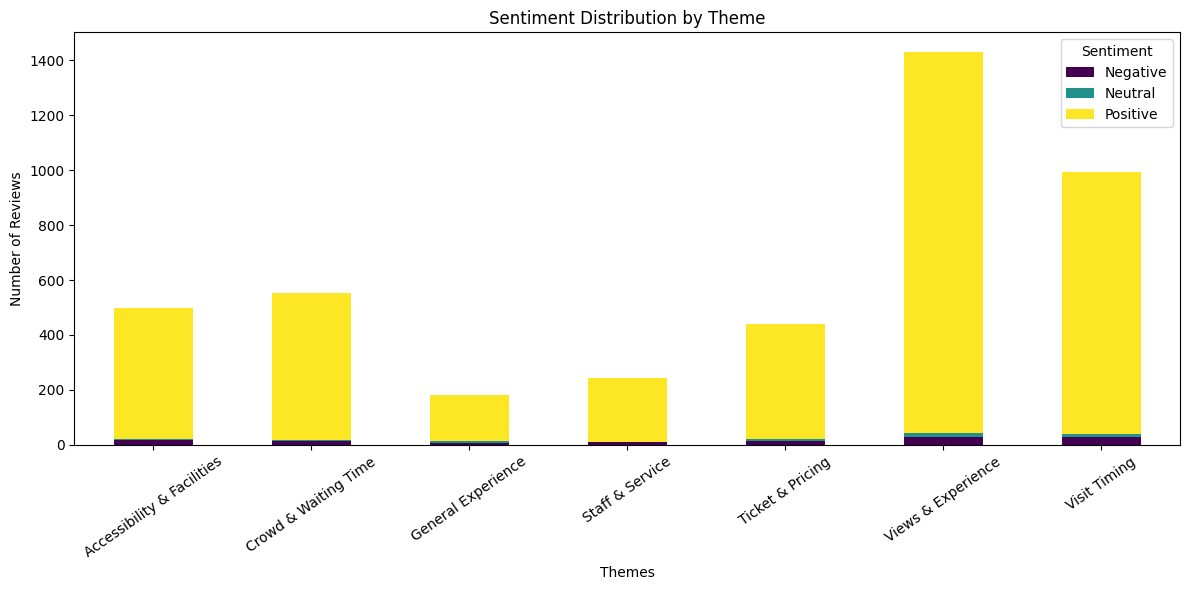

In [ ]:
theme_sentiment.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    colormap="viridis"
)

plt.title("Sentiment Distribution by Theme")
plt.xlabel("Themes")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=35)

plt.legend(title="Sentiment")
plt.tight_layout()
plt.show()

In [ ]:
# Extract Negative Reviews

negative_reviews = df[
    df["Transformer_Sentiment"] == "Negative"
].copy()

print("Total Negative Reviews:", len(negative_reviews))

display(
    negative_reviews[
        [
            "Text",
            "Transformer_Sentiment",
            "Transformer_Score",
            "Themes"
        ]
    ].head(20)
)

Total Negative Reviews: 76


,Text,Transformer_Sentiment,Transformer_Score,Themes
57,Plan to do lots of walking and lots of waiting...,Negative,0.768472,"[Crowd & Waiting Time, Staff & Service]"
81,We went at 8pm. There is glass all around it a...,Negative,0.658636,[Views & Experience]
83,"The Eiffel Tower is iconic, but the overall ex...",Negative,0.685168,"[Crowd & Waiting Time, Views & Experience]"
146,We booked a walking tour. Not worth it. Just q...,Negative,0.643203,"[Crowd & Waiting Time, Accessibility & Facilit..."
180,They canceled our booking to go to the top bec...,Negative,0.866879,"[Ticket & Pricing, Visit Timing]"
191,"I would recommend to go to the second floor, i...",Negative,0.794786,"[Ticket & Pricing, Staff & Service]"
193,Better to view from a distance. The view highe...,Negative,0.576089,"[Crowd & Waiting Time, Views & Experience]"
220,It's a shame that one of the world wonders is...,Negative,0.800896,[Ticket & Pricing]
255,Truly awful experience with spectacular views....,Negative,0.866911,"[Crowd & Waiting Time, Views & Experience]"
256,"It's a big, rusty radio tower, that someone co...",Negative,0.729719,"[Ticket & Pricing, Visit Timing]"


In [ ]:
# Expand Negative Review Themes

negative_theme_df = negative_reviews.explode("Themes")

# Count Negative Reviews by Theme

negative_theme_counts = (
    negative_theme_df["Themes"]
    .value_counts()
)

print("Negative Reviews by Theme:")

display(
    negative_theme_counts.to_frame("Negative Review Count")
)

Negative Reviews by Theme:


,Negative Review Count
Themes,
Views & Experience,44
Crowd & Waiting Time,30
Visit Timing,27
Ticket & Pricing,22
Staff & Service,17
Accessibility & Facilities,16
General Experience,7


In [ ]:
# Rule-Based Business Recommendations

recommendations = {

    "Ticket & Pricing":
        "Provide transparent ticket pricing and improve booking options.",

    "Crowd & Waiting Time":
        "Improve queue management and introduce better visitor flow systems.",

    "Views & Experience":
        "Maintain viewing areas and improve the overall visitor experience.",

    "Visit Timing":
        "Provide real-time visitor updates and recommend suitable visiting hours.",

    "Accessibility & Facilities":
        "Improve accessibility, elevators and visitor facilities.",

    "Staff & Service":
        "Provide staff training and improve visitor support.",

    "General Experience":
        "Collect detailed visitor feedback and identify common complaints."
}

print("AI Business Recommendations\\n")

for theme, count in negative_theme_counts.items():

    print(f"Theme: {theme}")
    print(f"Negative Reviews: {count}")
    print("Recommendation:", recommendations.get(theme))
    print("-" * 60)

AI Business Recommendations\n
Theme: Views & Experience
Negative Reviews: 44
Recommendation: Maintain viewing areas and improve the overall visitor experience.
------------------------------------------------------------
Theme: Crowd & Waiting Time
Negative Reviews: 30
Recommendation: Improve queue management and introduce better visitor flow systems.
------------------------------------------------------------
Theme: Visit Timing
Negative Reviews: 27
Recommendation: Provide real-time visitor updates and recommend suitable visiting hours.
------------------------------------------------------------
Theme: Ticket & Pricing
Negative Reviews: 22
Recommendation: Provide transparent ticket pricing and improve booking options.
------------------------------------------------------------
Theme: Staff & Service
Negative Reviews: 17
Recommendation: Provide staff training and improve visitor support.
------------------------------------------------------------
Theme: Accessibility & Facilities
N

In [ ]:
import torch
import pandas as pd
import json
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForCausalLM

In [ ]:
model_name = "Qwen/Qwen2.5-3B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=torch.float16,
    device_map="auto"
)

print("LLM Model Loaded Successfully!")
print("Device:", model.device)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

LLM Model Loaded Successfully!
Device: cuda:0


In [ ]:
def analyze_review(review):

    prompt = f"""
You are an expert Business Analyst.

Analyze the following customer review.

Customer Review:
{review}

Provide the output in this format:

Sentiment: Positive / Negative / Neutral / Mixed

Main Issue:
Mention the main issue in one or two sentences.

Key Theme:
Identify the main theme such as:
Ticket & Pricing, Crowd & Waiting Time,
Views & Experience, Visit Timing,
Accessibility & Facilities, Staff & Service,
General Experience.

Business Recommendation:
Provide one practical recommendation.

Keep the answer clear and concise.
"""

    messages = [
        {
            "role": "system",
            "content": "You are a professional customer review analyst."
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    text_input = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text_input,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():

        outputs = model.generate(
            **inputs,
            max_new_tokens=300,
            do_sample=False,
            repetition_penalty=1.1
        )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return response

In [ ]:
import pandas as pd

# Check if the raw file is available and load/clean it
try:
    df = pd.read_csv("/content/google_maps_reviews (1).csv")
    print("Loaded raw dataset successfully!")

    # 1. Map columns
    df = pd.DataFrame({
        "Text": df["snippet"].copy() if "snippet" in df.columns else df.get("extracted_snippet", ""),
        "Rating": df["rating"].copy()
    })
    if "iso_date_of_last_edit" in df.columns:
        df["Date"] = df["iso_date_of_last_edit"].copy()
    if "user" in df.columns:
        df["Author"] = df["user"].copy()

    # 2. Re-apply cleaning
    df["Text"] = df["Text"].astype("string").str.strip()
    df["Rating"] = pd.to_numeric(df["Rating"], errors="coerce")
    df = df.dropna(subset=["Text", "Rating"]).copy()
    df = df[df["Text"].str.strip().ne("")].copy()
    df = df[df["Rating"].between(1, 5)].copy()
    df = df.drop_duplicates(subset=["Text", "Rating"], keep="first").reset_index(drop=True)

    # Save it back so we have the cleaned file for the future
    df.to_csv("/content/google_maps_reviews_cleaned.csv", index=False)
    print("Dataset cleaned, reconstructed, and saved to '/content/google_maps_reviews_cleaned.csv'!")
    print("Shape:", df.shape)
    display(df.head())
except FileNotFoundError:
    print("Error: Neither the cleaned file nor the raw review CSV could be found in /content.")

Loaded raw dataset successfully!
Dataset cleaned, reconstructed, and saved to '/content/google_maps_reviews_cleaned.csv'!
Shape: (1997, 2)


,Text,Rating
0,Visiting the Eiffel Tower was truly the highli...,5.0
1,Visiting the Eiffel Tower was a truly unforget...,5.0
2,We visited the Eiffel Tower with our three kid...,5.0
3,Visiting the Eiffel Tower in winter was an unf...,5.0
4,Visiting the Eiffel Tower in Paris is genuinel...,4.0


In [ ]:
sample_review = df["Text"].iloc[0]

result = analyze_review(sample_review)

print("CUSTOMER REVIEW:")
print(sample_review)

print("\nLLM ANALYSIS:")
print(result)

CUSTOMER REVIEW:
Visiting the Eiffel Tower was truly the highlight of our trip to Paris! Seeing this iconic landmark in person is an incredible experience that words can hardly describe. The architecture is breathtaking, and the structure is even more grand and majestic up close.
​We took the lift to the top, and the panoramic views of Paris were absolutely magnificent! You can see the whole city, the Seine River, and all the famous monuments from above. We also visited during the evening, and watching the tower sparkle with thousands of lights at night was purely magical. It creates a dreamlike atmosphere that you will remember forever.
​The area around the tower (Champ de Mars) is very lively and clean, perfect for taking photos or having a relaxing walk. The staff and security were well-organized, making the entry and line movement smooth despite the crowd.
​Pro tip: It is best to book your tickets online in advance to save time. Whether you visit during the day or at night, the Eif

In [ ]:
def analyze_review(review):

    prompt = f"""
You are an accurate customer review analyst.

Analyze ONLY the information explicitly mentioned
in the customer review.

Customer Review:
{review}

Rules:
1. Do not invent problems or complaints.
2. If the review has no complaint, write:
   Main Issue: No specific issue reported.
3. Do not assume crowd or waiting problems.
4. Recommendations must be based on actual review content.
5. If no improvement is needed, suggest maintaining
   the current service quality.

Output:

Sentiment:
Main Issue:
Key Theme:
Business Recommendation:
"""

    messages = [
        {
            "role": "system",
            "content": "You are a factual and reliable business analyst."
        },
        {
            "role": "user",
            "content": prompt
        }
    ]

    text_input = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text_input,
        return_tensors="pt"
    ).to(model.device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=250,
            do_sample=False,
            repetition_penalty=1.1
        )

    response = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[1]:],
        skip_special_tokens=True
    )

    return response

In [ ]:
result = analyze_review(sample_review)
print(result)

Sentiment:
Positive

Main Issue:
No specific issue reported.

Key Theme:
The reviewer had a highly positive experience visiting the Eiffel Tower, praising its architectural beauty, panoramic views, and overall ambiance. They recommend it as a must-visit destination in Paris.

Business Recommendation:
Maintain the current service quality by continuing to ensure efficient ticket booking processes through online channels, which helps manage crowds effectively. Additionally, continue providing excellent customer service and ensuring the cleanliness and organization of the surrounding areas like Champ de Mars.


In [ ]:
from tqdm.auto import tqdm

sample_df = df.head(10).copy()

llm_results = []

for review in tqdm(sample_df["Text"]):
    result = analyze_review(review)
    llm_results.append(result)

sample_df["LLM_Analysis"] = llm_results

display(sample_df[["Text", "LLM_Analysis"]])

  0%|          | 0/10 [00:00<?, ?it/s]

,Text,LLM_Analysis
0,Visiting the Eiffel Tower was truly the highli...,Sentiment:\nPositive\n\nMain Issue:\nNo specif...
1,Visiting the Eiffel Tower was a truly unforget...,Sentiment: Positive\n\nMain Issue: No specific...
2,We visited the Eiffel Tower with our three kid...,Sentiment: Positive\n\nMain Issue: No specific...
3,Visiting the Eiffel Tower in winter was an unf...,Sentiment: Positive\n\nMain Issue: No specific...
4,Visiting the Eiffel Tower in Paris is genuinel...,Sentiment: Positive\n\nMain Issue: No specific...
5,Visiting the Eiffel Tower in the morning was s...,Sentiment: Positive\n\nMain Issue: No specific...
6,The Eiffel Tower is truly one of the most icon...,Sentiment: Positive\n\nMain Issue: No specific...
7,Great day to visit - no queues - just turned u...,Sentiment: Positive\n\nMain Issue: No specific...
8,The Eiffel Tower was one of the highlights of ...,Sentiment: Positive\n\nMain Issue: No specific...
9,I'd recommend everyone to book tickets in adva...,Sentiment: Positive\n\nMain Issue: No specific...


In [ ]:
# Save as CSV
sample_df.to_csv(
    "llm_business_insights_10.csv",
    index=False,
    encoding="utf-8-sig"
)

# Save as Excel
sample_df.to_excel(
    "llm_business_insights_10.xlsx",
    index=False
)

print("CSV and Excel files saved successfully!")

CSV and Excel files saved successfully!


In [ ]:
import os

print("Available CSV Files:")

for file in os.listdir("/content"):
    if file.endswith((".csv", ".xlsx")):
        print(file)

Available CSV Files:
google_maps_reviews (1).csv
llm_business_insights_10.csv
llm_full_analysis_checkpoint.csv
google_maps_reviews_cleaned.csv
llm_business_insights_10.xlsx


In [ ]:
import pandas as pd
import os

files = [
    "google_maps_reviews (1).csv",
    "google_maps_reviews_cleaned.csv",
    "llm_business_insights_10.csv",
    "llm_full_analysis_checkpoint.csv"
]

for file in files:
    path = "/content/" + file

    if os.path.exists(path):
        data = pd.read_csv(path)

        print("\nFile:", file)
        print("Shape:", data.shape)
        print("Columns:", data.columns.tolist())


File: google_maps_reviews (1).csv
Shape: (2000, 15)
Columns: ['position', 'link', 'rating', 'date', 'iso_date', 'iso_date_of_last_edit', 'images', 'source', 'review_id', 'user', 'snippet', 'extracted_snippet', 'details', 'likes', 'videos']

File: google_maps_reviews_cleaned.csv
Shape: (1997, 2)
Columns: ['Text', 'Rating']

File: llm_business_insights_10.csv
Shape: (10, 3)
Columns: ['Text', 'Rating', 'LLM_Analysis']

File: llm_full_analysis_checkpoint.csv
Shape: (1997, 3)
Columns: ['Review_ID', 'Text', 'LLM_Analysis']


In [ ]:
# Force-install compatible dependencies to resolve the huggingface_hub conflict
!pip install -q --upgrade huggingface_hub gradio

In [ ]:
import sys
import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Force reload huggingface_hub and gradio modules to clear out Colab's memory cache completely
for module in list(sys.modules.keys()):
    if "huggingface_hub" in module or "gradio" in module:
        sys.modules.pop(module, None)

import gradio as gr

# Fallback recommendations dictionary
recommendations = {
    "Ticket & Pricing":
        "Provide transparent ticket pricing and improve booking options.",
    "Crowd & Waiting Time":
        "Improve queue management and introduce better visitor flow systems.",
    "Views & Experience":
        "Maintain viewing areas and improve the overall visitor experience.",
    "Visit Timing":
        "Provide real-time visitor updates and recommend suitable visiting hours.",
    "Accessibility & Facilities":
        "Improve accessibility, elevators and visitor facilities.",
    "Staff & Service":
        "Provide staff training and improve visitor support.",
    "General Experience":
        "Collect detailed visitor feedback and identify common complaints."
}

# 1. Load the dataset with full details
try:
    # Load the original raw dataset to retrieve 'iso_date_of_last_edit'
    raw_df = pd.read_csv("/content/google_maps_reviews (1).csv")

    # Re-apply matching logic from previous stages
    df = pd.DataFrame({
        "Text": raw_df["snippet"].copy() if "snippet" in raw_df.columns else raw_df.get("extracted_snippet", ""),
        "Rating": pd.to_numeric(raw_df["rating"], errors="coerce"),
        "Date": raw_df["iso_date_of_last_edit"].copy() if "iso_date_of_last_edit" in raw_df.columns else None
    })
    df = df.dropna(subset=["Text", "Rating"]).copy()
    df = df[df["Text"].str.strip().ne("")].copy()
    df = df[df["Rating"].between(1, 5)].copy()
    df = df.drop_duplicates(subset=["Text", "Rating"], keep="first").reset_index(drop=True)

    # Add placeholder sentiment / themes if not processed to avoid crash
    from nltk.sentiment.vader import SentimentIntensityAnalyzer
    import nltk
    nltk.download("vader_lexicon", quiet=True)
    sid = SentimentIntensityAnalyzer()
    df["Sentiment_score"] = df["Text"].apply(lambda x: sid.polarity_scores(str(x))["compound"])
    df["Sentiment_label"] = df["Sentiment_score"].apply(lambda s: "Positive" if s > 0.05 else ("Negative" if s < -0.05 else "Neutral"))
    df["Transformer_Sentiment"] = df["Sentiment_label"]  # Fallback to VADER sentiment labels

    # Re-detect themes
    import re
    theme_keywords = {
        "Ticket & Pricing": ["ticket", "price", "expensive", "cheap", "cost", "booking", "book", "payment", "inexpensive", "fee"],
        "Crowd & Waiting Time": ["crowd", "queue", "queues", "waiting", "wait", "busy", "line", "long wait"],
        "Views & Experience": ["view", "beautiful", "amazing", "iconic", "experience", "panorama", "spectacular", "scenery", "highlight"],
        "Visit Timing": ["morning", "evening", "afternoon", "night", "sunset", "winter", "summer", "day", "lights"],
        "Accessibility & Facilities": ["stairs", "elevator", "lift", "wheelchair", "accessible", "toilet", "restroom", "facility", "access"],
        "Staff & Service": ["staff", "employee", "guide", "service", "security", "helpful", "friendly", "rude"]
    }

    def detect_themes(text):
        text = str(text).lower()
        matched_themes = []
        for theme, keywords in theme_keywords.items():
            for keyword in keywords:
                pattern = r"\b" + re.escape(keyword) + r"\b"
                if re.search(pattern, text):
                    matched_themes.append(theme)
                    break
        if not matched_themes:
            matched_themes.append("General Experience")
        return matched_themes

    df["Themes"] = df["Text"].apply(detect_themes)

except Exception as e:
    print(f"Warning during data recovery: {e}")

# Prepare data for dashboard visualizations
def generate_dashboard_plots():
    # 1. Monthly Sentiment Trend with explicit chronological sorting
    df['Parsed_Date'] = pd.to_datetime(df['Date'], errors='coerce', utc=True)
    df['Month'] = df['Parsed_Date'].dt.to_period('M').astype(str)

    # Generate cross-tabulation and sort index to ensure proper timeline sequence
    trend_df = pd.crosstab(df['Month'], df['Sentiment_label']).reset_index()
    trend_df = trend_df.sort_values(by='Month').reset_index(drop=True)

    for col in ['Positive', 'Neutral', 'Negative']:
        if col not in trend_df.columns:
            trend_df[col] = 0

    fig1, ax1 = plt.subplots(figsize=(10, 4.5))
    sns.lineplot(data=trend_df, x='Month', y='Positive', marker='o', label='Positive', color='#2ecc71', ax=ax1)
    sns.lineplot(data=trend_df, x='Month', y='Negative', marker='o', label='Negative', color='#e74c3c', ax=ax1)
    ax1.set_title("Eiffel Tower Sentiment Trend Over Time")
    ax1.set_xlabel("Month (Chronological)")
    ax1.set_ylabel("Number of Reviews")
    plt.xticks(rotation=45)
    plt.tight_layout()

    # 2. Top Recurring Negative Themes
    fig2, ax2 = plt.subplots(figsize=(10, 4.5))
    negative_themes = df[df['Transformer_Sentiment'] == 'Negative'].explode('Themes')
    if len(negative_themes) > 0:
        theme_data = negative_themes['Themes'].value_counts().reset_index()
        theme_data.columns = ['Theme', 'Count']
        sns.barplot(data=theme_data.head(5), x='Count', y='Theme', hue='Theme', palette='Reds_r', legend=False, ax=ax2)
    ax2.set_title("Top Recurring Negative Themes")
    ax2.set_xlabel("Count of Negative Reviews")
    plt.tight_layout()

    return fig1, fig2

# Define real-time text analysis function for the user interface
def analyze_custom_review(user_review):
    if not user_review.strip():
        return "Please enter a valid review."
    try:
        return analyze_review(user_review)
    except Exception as e:
        return f"LLM failed or is not loaded. Details: {str(e)}"

# Set up the theme / recommendation lookup table for the UI
recommendation_text = "### Key Actionable Business Improvements:\n"
for theme, rec in recommendations.items():
    recommendation_text += f"- **{theme}**: {rec}\n"

# Build the Gradio blocks dashboard
with gr.Blocks() as demo:
    gr.Markdown("# 🗼 Eiffel Tower Customer Review Insights Dashboard")
    gr.Markdown("Interactive dashboard displaying real-time analytics, sentiment trends, recurring feedback themes, and AI-driven business recommendations.")

    with gr.Tab("📊 Visual Analytics & Trends"):
        with gr.Row():
            trend_plot = gr.Plot(label="Sentiment Trend")
            theme_plot = gr.Plot(label="Top Negative Themes")

        gr.Markdown(recommendation_text)

    with gr.Tab("🧠 Interactive Review Analyzer"):
        gr.Markdown("### Submit a custom review to test the fine-tuned Business Analyst LLM:")
        review_input = gr.Textbox(placeholder="Write your review here (e.g. The staff was super helpful, but the elevator line was too slow...)", label="Customer Review")
        analyze_btn = gr.Button("Run Business Analysis", variant="primary")
        analysis_output = gr.Textbox(label="AI Business Analyst Output", lines=10)

        analyze_btn.click(fn=analyze_custom_review, inputs=review_input, outputs=analysis_output)

    # FIXED: Place the load callback within the gr.Blocks context
    demo.load(
        fn=generate_dashboard_plots,
        inputs=None,
        outputs=[trend_plot, theme_plot]
    )

# Launch with share=True to generate a public link
demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e4f97b8c3f04376994.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [ ]:
# Inspect the uniquely grouped months and sentiment categories
df['Parsed_Date'] = pd.to_datetime(df['Date'], errors='coerce', utc=True)
df['Month_Period'] = df['Parsed_Date'].dt.to_period('M').astype(str)

print("Unique Month Values in 'Month':")
print(df['Month_Period'].unique()[:20])
print("\nValue counts for the top months:")
print(df['Month_Period'].value_counts().head(10))

# Let's inspect the grouped sentiment data used in the trend plot
trend_data_check = pd.crosstab(df['Month_Period'], df['Sentiment_label']).reset_index()
display(trend_data_check.head(10))

Unique Month Values in 'Month':
['2026-09' '2026-10' '2026-08' '2026-11' '2026-06' '2026-07' '2026-05'
 '2026-04' '2026-03' '2025-10' '2026-02' '2025-12' '2026-01' '2025-08'
 '2025-11' '2025-09' '2025-06' '2025-07' '2025-05' '2025-04']

Value counts for the top months:
Month_Period
2026-06    191
2026-10    147
2025-07    122
2025-08    117
2026-08    104
2026-03    103
2025-10     96
2025-06     91
2025-05     90
2025-12     88
Name: count, dtype: int64


/tmp/ipykernel_10417/1636381112.py:3: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df['Month_Period'] = df['Parsed_Date'].dt.to_period('M').astype(str)


Sentiment_label,Month_Period,Negative,Neutral,Positive
0,2018-07,0,0,1
1,2019-09,0,0,1
2,2022-10,0,0,5
3,2023-01,0,0,5
4,2023-02,0,0,1
5,2023-03,0,0,1
6,2023-04,0,0,1
7,2023-05,0,0,5
8,2023-06,0,0,3
9,2023-07,0,0,8
